# 01. Análise Exploratória de Dados (EDA) — Manutenção Preventiva

## Contexto e Objetivo
Em operações industriais, falhas inesperadas geram custos elevados de parada (*downtime*) e riscos operacionais, enquanto manutenções preventivas em excesso desperdiçam recursos em equipamentos saudáveis. O objetivo desta etapa é investigar os dados de sensores e operação para compreender o comportamento dos ativos, validar a integridade dos registros e identificar padrões associados às falhas antes da modelagem preditiva.

## Roteiro de Exploração
1. **Configuração e Ingestão:** Importação de pacotes e leitura segura dos dados brutos.
2. **Inspeção Estrutural e Integridade:** Avaliação de dimensões, tipagem, valores ausentes, duplicatas e possíveis variáveis sem valor preditivo (ex.: IDs).
3. **Análise da Variável Alvo (Falhas):** Verificação da taxa de falha (desbalanceamento de classes) e distribuição dos modos de falha, se aplicável.
4. **Análise Univariada:** Comportamento individual das variáveis operacionais (distribuições, assimetrias e validação física de *outliers*).
5. **Análise Bivariada e Multivariada:** Cruzamento das variáveis de processo com a ocorrência de falhas e correlações entre sensores (ex.: relação entre torque, rotação e temperatura).
6. **Síntese e Direcionamento:** Consolidação dos achados para guiar a engenharia de atributos (*feature engineering*) e a escolha de algoritmos/métricas.

---
## 1. Configuração do Ambiente e Carregamento dos Dados
Importamos as bibliotecas essenciais, padronizamos a visualização das tabelas/gráficos e carregamos a base bruta utilizando caminhos relativos para garantir reprodutibilidade.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Configurações de exibição do Pandas para melhor leitura
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Padrão visual dos gráficos
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

In [4]:
# Define o diretório raiz do projeto de forma dinâmica
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

# Caminhos estruturados
DATA_PATH = PROJECT_DIR / 'data' / 'raw' / 'dados_aula.csv'
DICT_PATH = PROJECT_DIR / 'docs' / 'dicionario_dados.md'

# Carregamento da base de dados bruta
df = pd.read_csv(DATA_PATH)

print(f"Base carregada: {DATA_PATH.relative_to(PROJECT_DIR)}")
print(f"Dimensões: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
display(df.head())

Base carregada: data/raw/dados_aula.csv
Dimensões: 9,203 linhas x 14 colunas


,sequencia_peca,codigo_peca,classe_peca,temp_entrada_c,temp_processo_c,velocidade_rpm,torque_nm,uso_ferramenta_min,parada,modo_b,modo_c,modo_d,modo_a,modo_e
0,1,P268880,padrao,25.00,35.40,1551,42.80,0,0,0,0,0,0,0
1,2,E107582,economica,25.10,35.60,1407,46.40,3,0,0,0,0,0,0
2,3,E629356,economica,25.00,35.30,1497,49.50,5,0,0,0,0,0,0
3,4,E778496,economica,25.10,35.40,1432,39.50,8,0,0,0,0,0,0
4,5,P171652,padrao,25.00,35.40,1425,41.90,11,0,0,0,0,0,0


In [5]:
# Exibe o dicionário de dados para contextualizar as variáveis
if DICT_PATH.exists():
    print(DICT_PATH.read_text(encoding='utf-8'))

# Dicionário de dados: paradas de uma fresadora

A base registra o histórico de produção de uma fresadora industrial. Cada linha é uma peça usinada: as leituras dos sensores naquele ciclo e se a máquina parou.

| | |
|---|---|
| Linhas | 9.203 |
| Colunas | 14 |
| Paradas | 314 (3,41%) |
| Valores ausentes | 0 |

Arquivo: `data/dados_aula.csv`. As linhas estão na ordem em que as peças foram produzidas.

## Sequência e identificador

| Coluna | Tipo | Significado |
|---|---|---|
| `sequencia_peca` | inteira | Posição da peça na sequência de produção, de 1 a 9.203. Indica o tempo: a peça 1 foi a primeira, a 9.203 a última. Serve para dividir os dados em treino e teste respeitando o tempo. Não deve ser usada como variável do modelo. |
| `codigo_peca` | texto | Código único da peça: uma letra seguida de seis dígitos. A letra repete a classe da peça. Não deve ser usado como variável do modelo. |

## Variáveis de entrada

São as seis leituras disponíveis antes de saber se a máquina parou. É 

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9203 entries, 0 to 9202
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sequencia_peca      9203 non-null   int64  
 1   codigo_peca         9203 non-null   str    
 2   classe_peca         9203 non-null   str    
 3   temp_entrada_c      9203 non-null   float64
 4   temp_processo_c     9203 non-null   float64
 5   velocidade_rpm      9203 non-null   int64  
 6   torque_nm           9203 non-null   float64
 7   uso_ferramenta_min  9203 non-null   int64  
 8   parada              9203 non-null   int64  
 9   modo_b              9203 non-null   int64  
 10  modo_c              9203 non-null   int64  
 11  modo_d              9203 non-null   int64  
 12  modo_a              9203 non-null   int64  
 13  modo_e              9203 non-null   int64  
dtypes: float64(3), int64(9), str(2)
memory usage: 1006.7 KB


In [7]:
# Separando grupos de colunas
cols_sensores = [
    "temp_entrada_c",
    "temp_processo_c",
    "velocidade_rpm",
    "torque_nm",
    "uso_ferramenta_min",
]
cols_modos = ["modo_a", "modo_b", "modo_c", "modo_d", "modo_e"]

df[cols_sensores].describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
temp_entrada_c,9203.00,26.86,2.01,22.20,25.20,26.90,28.40,31.40
temp_processo_c,9203.00,36.86,1.48,32.60,35.70,36.90,37.90,40.70
velocidade_rpm,9203.00,1539.31,180.08,1166.00,1423.00,1503.00,1613.00,2883.00
torque_nm,9203.00,39.95,9.99,3.80,33.10,40.10,46.70,76.60
uso_ferramenta_min,9203.00,108.06,63.62,0.00,53.00,108.00,162.00,252.00


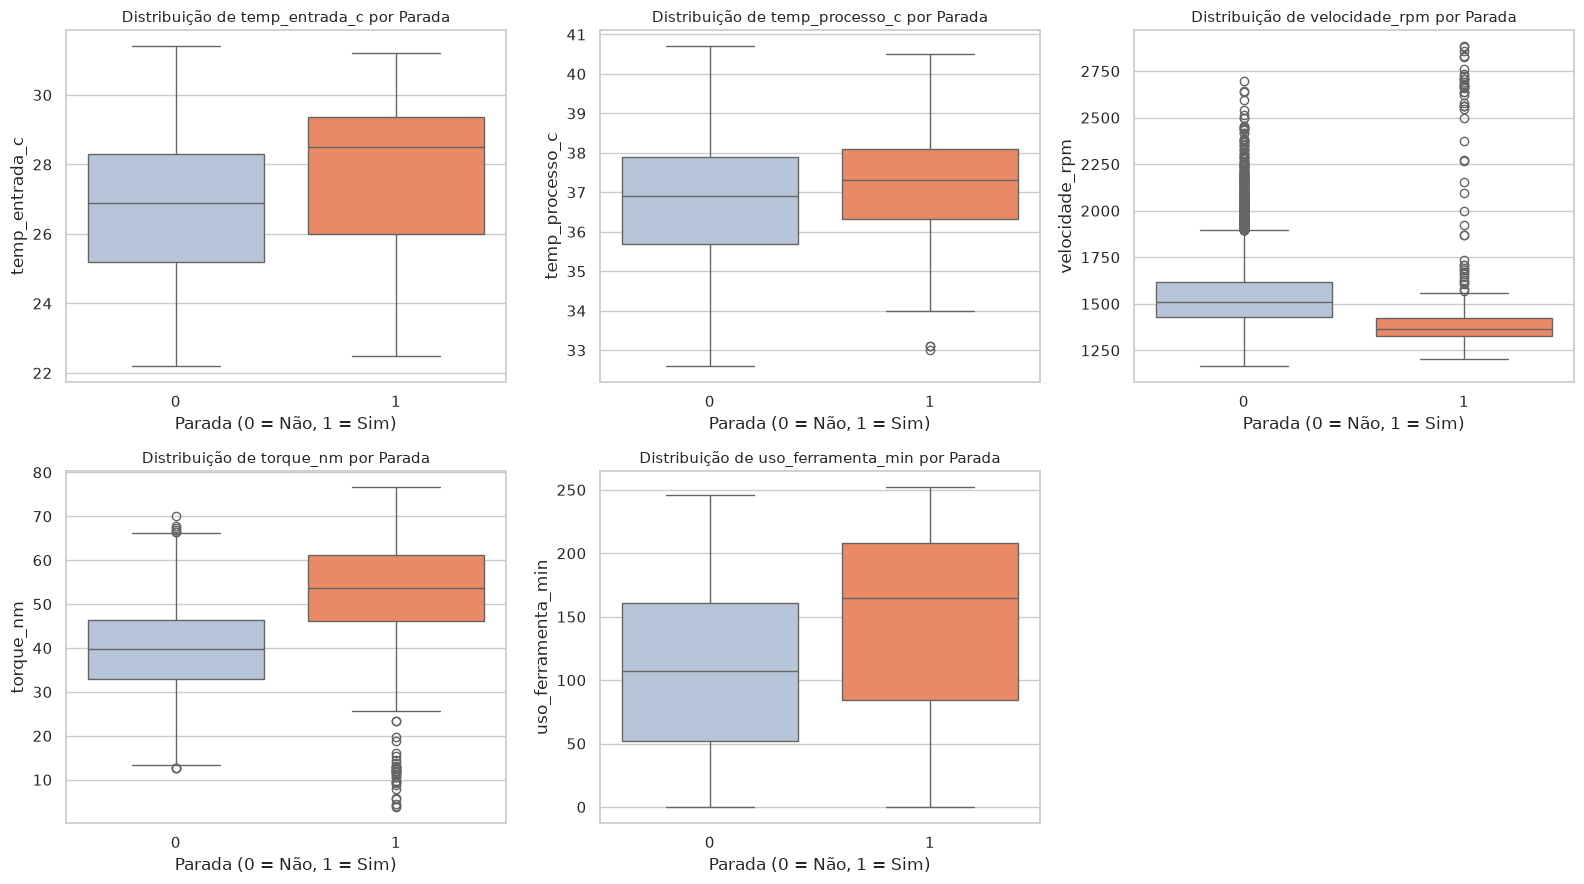

In [10]:
# Célula: Análise de distribuição dos sensores segmentada por parada
# Objetivo: Identificar visualmente sobreposição, assimetria e separação entre ciclos normais e com falha.

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

# Cores: azul suave para operação normal (0), coral/alaranjado para parada (1)
cores_parada = ["lightsteelblue", "coral"]

for i, col in enumerate(cols_sensores):
    sns.boxplot(
        data=df,
        x="parada",
        y=col,
        hue="parada",
        ax=axes[i],
        palette=cores_parada,
        legend=False,
    )
    axes[i].set_title(f"Distribuição de {col} por Parada", fontsize=11)
    axes[i].set_xlabel("Parada (0 = Não, 1 = Sim)")

# Ocultando o último subplot que sobra na grade 2x3
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

### Primeiras Impressões: Distribuição dos Sensores vs. Parada

A análise visual dos boxplots segmentados pelo alvo (`parada`) revela padrões operacionais e comportamentos físicos distintos:

1. **Temperaturas (`temp_entrada_c` e `temp_processo_c`):**
   * **Sobreposição acentuada:** Isoladamente, as distribuições de temperatura apresentam forte sobreposição entre ciclos normais e ciclos de falha. A mediana de `temp_entrada_c` é ligeiramente superior nos casos de parada (~28,5 °C contra ~27,0 °C), enquanto `temp_processo_c` exibe pouca variação de posição central.
   * **Hipótese:** O impacto térmico não reside nos valores absolutos, mas sim no diferencial térmico ($\Delta T = \text{temp\_processo} - \text{temp\_entrada}$). Casos de falha por dissipação de calor (`modo_c`) provavelmente dependem da perda desse gradiente e devem ser investigados via engenharia de atributos.

2. **Cinemática e Carga (`velocidade_rpm` e `torque_nm`):**
   * **Separabilidade clara com comportamento bimodal:** São as variáveis com maior capacidade discriminatória individual.
   * **Torque:** Na operação padrão, o torque concentra-se em ~40 Nm. Nas paradas, a mediana sobe para ~54 Nm (sobrecarga mecânica), mas destaca-se uma cauda inferior de *outliers* com valores críticos abaixo de 20 Nm.
   * **Velocidade:** A maioria das paradas ocorre em rotações mais baixas (~1.370 rpm, associadas ao torque elevado), porém há um grupo expressivo de falhas em rotações extremas (> 2.500 rpm).
   * **Hipótese:** Esses dois regimes nos extremos de rotação e torque sugerem modos de falha distintos (esforço excessivo na ponta de alto torque vs. perda de carga/potência na ponta de alta velocidade).

3. **Desgaste Mecânico (`uso_ferramenta_min`):**
   * **Aceleração do risco com a vida útil:** A mediana de uso da ferramenta salta de ~105 min (operação normal) para ~165 min nas paradas, com o terceiro quartil ultrapassando os 200 min.
   * O desgaste acumulado atua como um fator de amplificação: ferramentas próximas do fim de vida útil têm menor tolerância a picos de torque.

In [11]:
# Célula: Validação de unicidade e consistência de codigo_peca
# Objetivo: Garantir que cada peça possui identificador exclusivo e que a letra inicial corresponde à sua classe.

# 1. Checagem de valores duplicados
total_registros = len(df)
codigos_unicos = df["codigo_peca"].nunique()
duplicados = df["codigo_peca"].duplicated().sum()

print(f"Total de registros na base: {total_registros}")
print(f"Identificadores únicos em 'codigo_peca': {codigos_unicos}")
print(f"Quantidade de códigos duplicados: {duplicados}")

# 2. Checagem de integridade: a primeira letra do código bate com a classe?
mapa_classes = {"E": "economica", "P": "padrao", "R": "premium"}
letras_esperadas = df["codigo_peca"].str[0].map(mapa_classes)
inconsistencias_classe = (letras_esperadas != df["classe_peca"]).sum()

print(
    f"Inconsistências entre 'codigo_peca' e 'classe_peca': {inconsistencias_classe}"
)

# Asserção de integridade para rastreabilidade
assert (
    duplicados == 0
), "Atenção: existem identificadores de peça duplicados na base!"
assert (
    inconsistencias_classe == 0
), "Atenção: divergência entre a letra do código e a classe registrada!"

Total de registros na base: 9203
Identificadores únicos em 'codigo_peca': 9203
Quantidade de códigos duplicados: 0
Inconsistências entre 'codigo_peca' e 'classe_peca': 0


,classe_peca,total_pecas,total_paradas,taxa_parada_pct,participacao_producao_pct
0,economica,5527,219,3.96,60.06
1,padrao,2754,78,2.83,29.93
2,premium,922,17,1.84,10.02


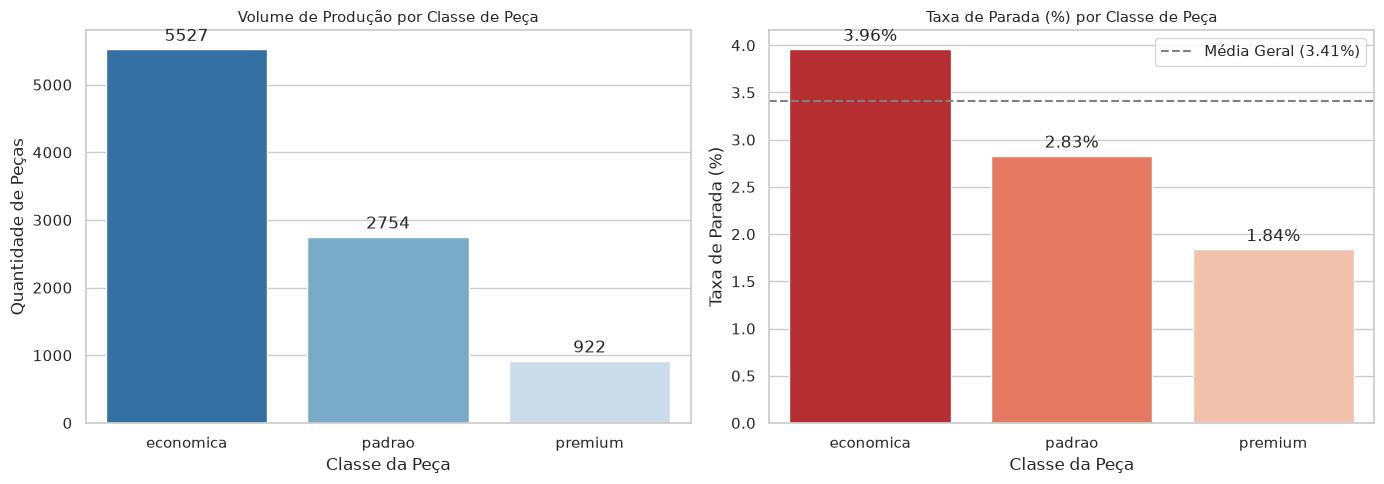

In [13]:
# Célula: Análise da taxa de paradas por classe de peça
# Objetivo: Quantificar se o risco de parada varia conforme a classe da peça (econômica, padrão ou premium)
# sem uso de funções anônimas (lambda) ou .apply, priorizando operações vetorizadas nativas.

# 1. Agregação com métodos nativos do pandas (count, sum, mean)
taxa_classe = (
    df.groupby("classe_peca")["parada"]
    .agg(total_pecas="count", total_paradas="sum", taxa_parada_pct="mean")
    .reset_index()
)

# 2. Cálculo percentual vetorizado direto
taxa_classe["taxa_parada_pct"] = (taxa_classe["taxa_parada_pct"] * 100).round(
    2
)
taxa_classe["participacao_producao_pct"] = (
    (taxa_classe["total_pecas"] / len(df)) * 100
).round(2)

# 3. Ordenação por taxa de falha para facilitar a visualização
taxa_classe = taxa_classe.sort_values(
    by="taxa_parada_pct", ascending=False
).reset_index(drop=True)
display(taxa_classe)

# 4. Visualização gráfica: Volume de Produção vs. Taxa de Falha
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Volume absoluto de peças usinadas por classe
sns.barplot(
    data=taxa_classe,
    x="classe_peca",
    y="total_pecas",
    palette="Blues_r",
    hue="classe_peca",
    legend=False,
    ax=ax1,
)
ax1.set_title("Volume de Produção por Classe de Peça", fontsize=11)
ax1.set_xlabel("Classe da Peça")
ax1.set_ylabel("Quantidade de Peças")

for p in ax1.patches:
    ax1.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points",
    )

# Gráfico 2: Taxa percentual de parada por classe
media_geral_pct = (df["parada"].mean() * 100).round(2)

sns.barplot(
    data=taxa_classe,
    x="classe_peca",
    y="taxa_parada_pct",
    palette="Reds_r",
    hue="classe_peca",
    legend=False,
    ax=ax2,
)
ax2.axhline(
    media_geral_pct,
    color="gray",
    linestyle="--",
    label=f"Média Geral ({media_geral_pct}%)",
)
ax2.set_title("Taxa de Parada (%) por Classe de Peça", fontsize=11)
ax2.set_xlabel("Classe da Peça")
ax2.set_ylabel("Taxa de Parada (%)")
ax2.legend()

for p in ax2.patches:
    ax2.annotate(
        f"{p.get_height():.2f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

### Relação entre Classe da Peça e Taxa de Parada

A análise da distribuição de volume e quebras por classe revela uma relação inversa entre a qualidade do lote usinado e a taxa de paradas:

1. **Assimetria de Risco:**
   * **Econômica (`E`):** Representa a maior fatia da produção (60,06%), mas concentra a maior taxa de paradas da operação (**3,96%**), ficando acima da média global da máquina (3,41%). É responsável por ~70% de todas as paradas registradas (219 de 314).
   * **Padrão (`P`):** Fica em patamar intermediário, com **2,83%** de taxa de falha para 29,93% do volume.
   * **Premium (`R`):** Apresenta a menor taxa de parada (**1,84%**), menos da metade do risco observado na classe econômica, embora represente apenas 10,02% da produção.

2. **Relevância para a Modelagem:**
   * A coluna `classe_peca` atua como um divisor de risco a priori.
   * O comportamento confirma a premissa de engenharia do dicionário de dados para o **Modo A (Sobre-esforço)**: ferramentas submetidas a esforços com materiais de menor controle dimensional/qualidade (como a linha econômica) tendem a falhar com maior frequência.

In [14]:
# Célula: Engenharia de Atributos Inicial (Física do Processo)
# Objetivo: Criar variáveis derivadas fundamentadas em princípios termodinâmicos e mecânicos.

import numpy as np

# 1. Diferencial térmico (Delta T) entre o processo e a entrada (°C)
# Relevante para monitorar a dissipação de calor (modo_c)
df["delta_temp_c"] = df["temp_processo_c"] - df["temp_entrada_c"]

# 2. Conversão de rotação (rpm) para velocidade angular (rad/s)
# Fator de conversão: 2 * pi / 60
df["velocidade_rad_s"] = df["velocidade_rpm"] * (2 * np.pi / 60)

# 3. Potência mecânica em Watts (W) e Quilowatts (kW)
# Relevante para limites operacionais de potência (modo_d)
df["potencia_w"] = df["torque_nm"] * df["velocidade_rad_s"]
df["potencia_kw"] = df["potencia_w"] / 1000

# Exibindo o resumo estatístico das variáveis criadas
cols_novas = ["delta_temp_c", "potencia_w", "potencia_kw"]
df[cols_novas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
delta_temp_c,9203.00,10.00,1.01,7.60,9.30,9.80,11.00,12.20
potencia_w,9203.00,6275.36,1070.35,1147.25,5550.82,6265.30,6998.68,10485.71
potencia_kw,9203.00,6.28,1.07,1.15,5.55,6.27,7.00,10.49


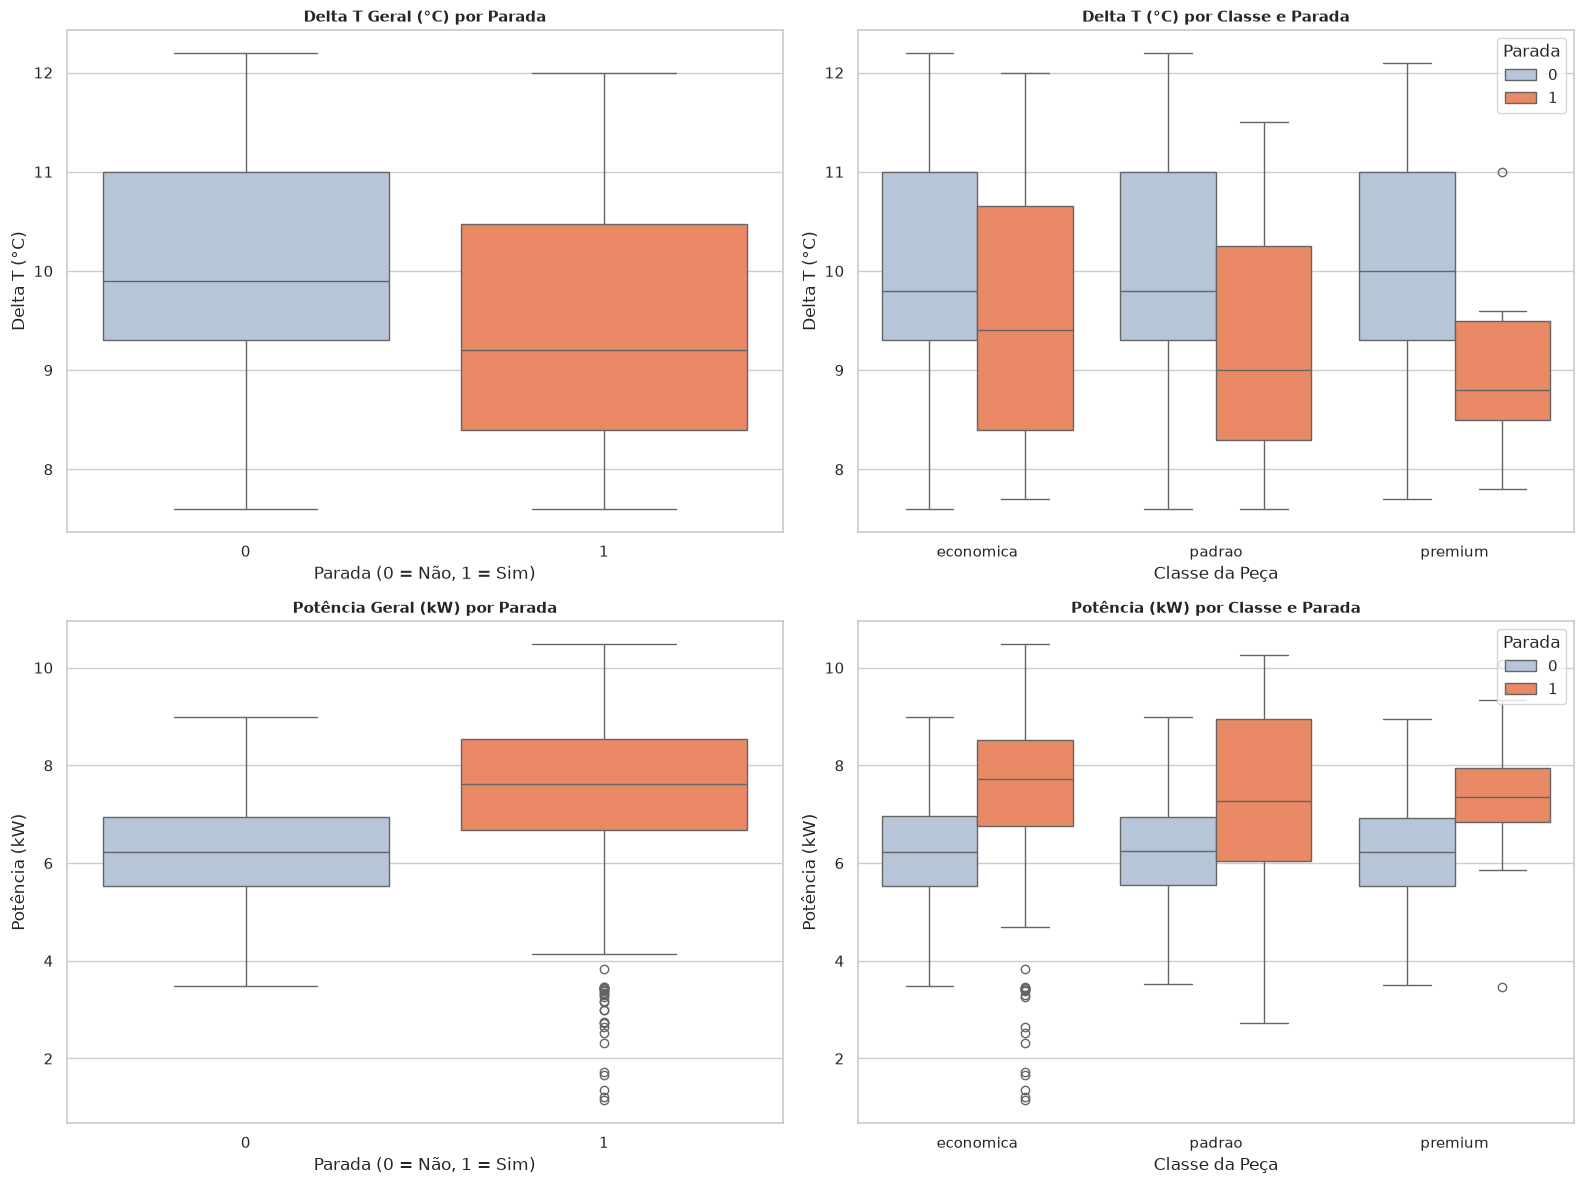

In [15]:
# Célula: Distribuição das novas variáveis (Geral vs. Segmentado por Classe)
# Objetivo: Identificar visualmente se os limites operacionais críticos de Delta T e Potência
# variam de acordo com o tipo de peça usinada e se separam bem as paradas.

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

cores_parada = ["lightsteelblue", "coral"]
ordem_classes = ["economica", "padrao", "premium"]

# ----------------------------------------------------
# Linha 1: Diferencial de Temperatura (delta_temp_c)
# ----------------------------------------------------
# 1.1 Visão Geral
sns.boxplot(
    data=df,
    x="parada",
    y="delta_temp_c",
    hue="parada",
    palette=cores_parada,
    legend=False,
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    "Delta T Geral (°C) por Parada", fontsize=11, fontweight="bold"
)
axes[0, 0].set_xlabel("Parada (0 = Não, 1 = Sim)")
axes[0, 0].set_ylabel("Delta T (°C)")

# 1.2 Visão por Classe
sns.boxplot(
    data=df,
    x="classe_peca",
    y="delta_temp_c",
    hue="parada",
    order=ordem_classes,
    palette=cores_parada,
    ax=axes[0, 1],
)
axes[0, 1].set_title(
    "Delta T (°C) por Classe e Parada", fontsize=11, fontweight="bold"
)
axes[0, 1].set_xlabel("Classe da Peça")
axes[0, 1].set_ylabel("Delta T (°C)")
axes[0, 1].legend(title="Parada", loc="upper right")

# ----------------------------------------------------
# Linha 2: Potência Mecânica (potencia_kw)
# ----------------------------------------------------
# 2.1 Visão Geral
sns.boxplot(
    data=df,
    x="parada",
    y="potencia_kw",
    hue="parada",
    palette=cores_parada,
    legend=False,
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    "Potência Geral (kW) por Parada", fontsize=11, fontweight="bold"
)
axes[1, 0].set_xlabel("Parada (0 = Não, 1 = Sim)")
axes[1, 0].set_ylabel("Potência (kW)")

# 2.2 Visão por Classe
sns.boxplot(
    data=df,
    x="classe_peca",
    y="potencia_kw",
    hue="parada",
    order=ordem_classes,
    palette=cores_parada,
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    "Potência (kW) por Classe e Parada", fontsize=11, fontweight="bold"
)
axes[1, 1].set_xlabel("Classe da Peça")
axes[1, 1].set_ylabel("Potência (kW)")
axes[1, 1].legend(title="Parada", loc="upper right")

plt.tight_layout()
plt.show()

### Análise Crítica: Delta T e Potência por Classe

A avaliação dos gráficos das variáveis derivadas em relação às paradas da máquina aponta três conclusões principais:

1. Diferencial Térmico (Delta T):
- Em regime normal de corte, a máquina opera com um Delta T estabilizado em torno de 10,0°C.
- Durante ocorrências de parada, há uma queda evidente desse gradiente térmico (mediana cai para 9,2°C). Isso confirma que a perda de capacidade de troca de calor (modo_c) é um forte indicador de falha.
- Na classe premium, as quebras ocorrem com valores ainda mais baixos de Delta T (abaixo de 9,5°C), sugerindo maior tolerância térmica do conjunto.

2. Demanda de Potência Mecânica:
- Falhas por sobrecarga: A potência sobe substancialmente em ciclos de quebra, passando da média de 6,28 kW para patamares entre 7,5 e 8,0 kW em todas as classes.
- Falhas por subpotência: As quebras com potências criticamente baixas (menores que 4,0 kW) concentram-se quase exclusivamente na classe econômica. Isso indica perda de carga ou rotação desregulada nesses lotes.